# Exploratory Data Analysis (EDA)

Goal: understand the data **before** modelling and justify the preprocessing decisions with numbers.

Decisions already taken (see `docs/data_quality.md`): top-5 leagues, target = last valuation between 1 April and 31 July of the year the season ends, league = league with most minutes, contract dropped.

> The player-season table built here is exploratory. In week 2 the same logic moves to `src/features.py`, with tests.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Run from the repository root so that `src` and `data/raw` are found
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import data_loader

DATA_DIR = ROOT / "data" / "raw"
TOP5 = {"GB1": "Premier League", "ES1": "LaLiga", "IT1": "Serie A",
        "L1": "Bundesliga", "FR1": "Ligue 1"}
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Load the tables

In [2]:
players = data_loader.load_players(DATA_DIR)
appearances = data_loader.load_appearances(DATA_DIR)
games = data_loader.load_games(DATA_DIR)
valuations = data_loader.load_valuations(DATA_DIR)
{name: len(table) for name, table in
 [("players", players), ("appearances", appearances), ("games", games), ("valuations", valuations)]}

{'players': 50149,
 'appearances': 1894350,
 'games': 88958,
 'valuations': 656301}

## 2. Build the player-season table

1. Keep league matches of the top 5 and add the season from `games`.
2. Sum minutes, goals and assists per player and season; the league is the one with most minutes.
3. Join the last valuation between 1 April and 31 July of the year the season ends (season 2024 = 2024/25 → valuations of 2025).

In [3]:
league_apps = (appearances[appearances.competition_id.isin(TOP5)]
               .merge(games[["game_id", "season"]], on="game_id"))

seasons = league_apps.groupby(["player_id", "season"], as_index=False).agg(
    minutes=("minutes_played", "sum"), goals=("goals", "sum"),
    assists=("assists", "sum"), matches=("game_id", "nunique"))

main_league = (league_apps.groupby(["player_id", "season", "competition_id"]).minutes_played.sum()
               .reset_index().sort_values("minutes_played")
               .drop_duplicates(["player_id", "season"], keep="last")
               .rename(columns={"competition_id": "league"}))
seasons = seasons.merge(main_league[["player_id", "season", "league"]], on=["player_id", "season"])

window = valuations[(valuations.market_value_in_eur > 0)
                    & valuations.date.dt.month.between(4, 7)].copy()
window["season"] = window.date.dt.year - 1
target = window.sort_values("date").drop_duplicates(["player_id", "season"], keep="last")

table = seasons.merge(target[["player_id", "season", "market_value_in_eur"]],
                      on=["player_id", "season"], how="left")
print(f"Player-seasons: {len(table):,}; with a valuation in the window: "
      f"{table.market_value_in_eur.notna().mean():.1%}")

Player-seasons: 36,669; with a valuation in the window: 91.4%


In [4]:
table = (table.dropna(subset=["market_value_in_eur"])
         .merge(players[["player_id", "date_of_birth", "position"]], on="player_id"))
season_end = pd.to_datetime((table.season + 1).astype(str) + "-06-30")
table["age"] = (season_end - table.date_of_birth).dt.days / 365.25
table["log_value"] = np.log10(table.market_value_in_eur)
table["goals_per90"] = table.goals / table.minutes * 90
table["league_name"] = table.league.map(TOP5)
table.head()

,player_id,season,minutes,goals,assists,matches,league,market_value_in_eur,date_of_birth,position,age,log_value,goals_per90,league_name
0,10,2012,2186,15,3,29,IT1,"2,000,000.00",1978-06-09,Attack,35.06,6.30,0.62,Serie A
1,10,2013,2018,7,5,25,IT1,"1,000,000.00",1978-06-09,Attack,36.06,6.00,0.31,Serie A
2,10,2014,1835,13,7,34,IT1,"1,000,000.00",1978-06-09,Attack,37.06,6.00,0.64,Serie A
3,26,2012,2781,0,0,31,L1,"5,000,000.00",1980-08-06,Goalkeeper,32.90,6.70,0.00,Bundesliga
4,26,2013,2700,0,0,30,L1,"5,000,000.00",1980-08-06,Goalkeeper,33.90,6.70,0.00,Bundesliga


## 3. Target: market value in euros vs. log scale

count        33,506.00
mean      9,215,441.26
std      14,963,758.02
min          25,000.00
25%       1,500,000.00
50%       3,500,000.00
75%      10,000,000.00
max     200,000,000.00
Name: market_value_in_eur, dtype: float64

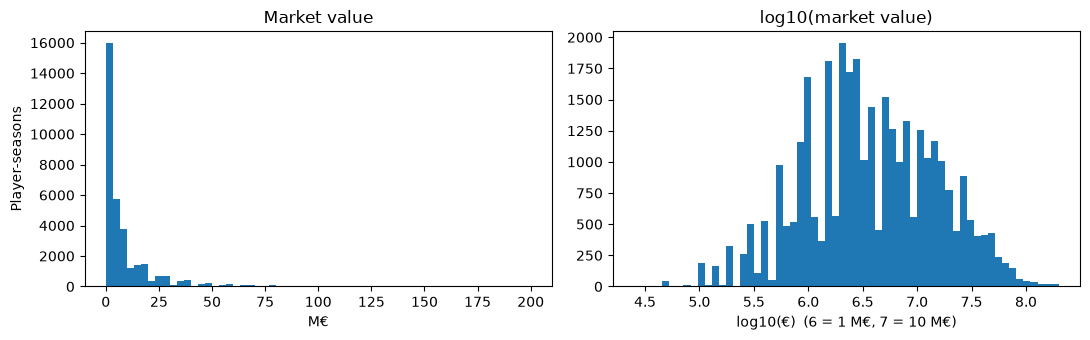

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(table.market_value_in_eur / 1e6, bins=60)
axes[0].set(title="Market value", xlabel="M€", ylabel="Player-seasons")
axes[1].hist(table.log_value, bins=60)
axes[1].set(title="log10(market value)", xlabel="log10(€)  (6 = 1 M€, 7 = 10 M€)")
plt.tight_layout()
table.market_value_in_eur.describe()

## 4. Minimum minutes: how much noise and how many rows?

,min_minutes,rows,max_goals_per90
0,0,33506,30.00
1,200,28734,1.89
2,450,25897,1.58
3,900,21274,1.58


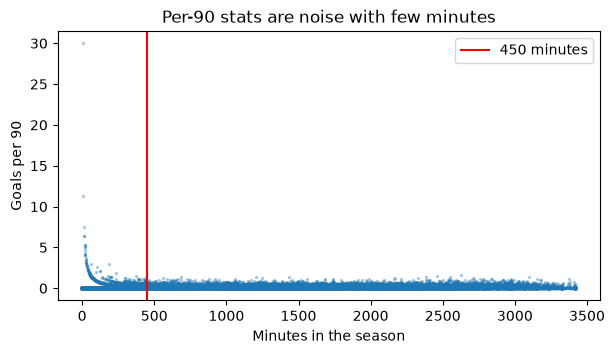

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.scatter(table.minutes, table.goals_per90, s=2, alpha=0.3)
ax.axvline(450, color="red", label="450 minutes")
ax.set(xlabel="Minutes in the season", ylabel="Goals per 90", title="Per-90 stats are noise with few minutes")
ax.legend()

pd.DataFrame({"min_minutes": [0, 200, 450, 900],
              "rows": [(table.minutes >= t).sum() for t in (0, 200, 450, 900)],
              "max_goals_per90": [table[table.minutes >= t].goals_per90.max() for t in (0, 200, 450, 900)]})

In [7]:
data = table[table.minutes >= 450].copy()
print(f"Rows kept with >= 450 minutes: {len(data):,}")

Rows kept with >= 450 minutes: 25,897


## 5. Value by age

age,17.00,18.00,19.00,20.00,21.00,22.00,23.00,24.00,25.00,26.00,...,28.00,29.00,30.00,31.00,32.00,33.00,34.00,35.00,36.00,37.00
median_value,"18,500,000.00","12,000,000.00","7,750,000.00","7,500,000.00","8,000,000.00","8,000,000.00","8,000,000.00","7,500,000.00","7,000,000.00","7,000,000.00",...,"6,000,000.00","5,500,000.00","4,800,000.00","3,500,000.00","2,500,000.00","2,000,000.00","1,500,000.00","1,000,000.00","800,000.00","625,000.00"
players,6.00,63.00,244.00,572.00,983.00,"1,411.00","1,875.00","2,073.00","2,214.00","2,359.00",...,"2,206.00","2,002.00","1,779.00","1,543.00","1,296.00",990.00,743.00,511.00,319.00,174.00


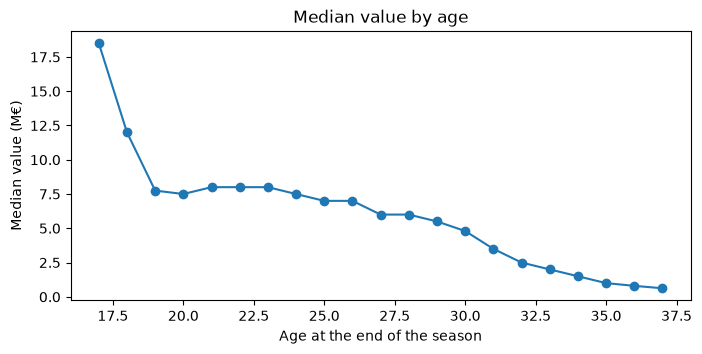

In [8]:
by_age = data.groupby(data.age.round()).agg(median_value=("market_value_in_eur", "median"),
                                             players=("player_id", "size")).loc[17:37]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(by_age.index, by_age.median_value / 1e6, marker="o")
ax.set(xlabel="Age at the end of the season", ylabel="Median value (M€)", title="Median value by age")
by_age.T

## 6. Value by position and league

league_name
Bundesliga        5,000,000.00
LaLiga            4,000,000.00
Ligue 1           3,500,000.00
Premier League   13,000,000.00
Serie A           4,500,000.00
Name: market_value_in_eur, dtype: float64

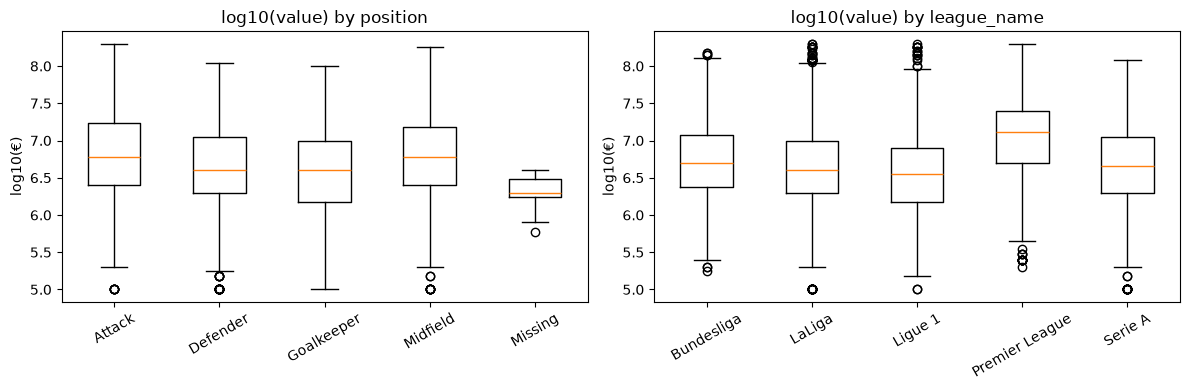

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column in zip(axes, ["position", "league_name"]):
    groups = data.groupby(column).log_value
    ax.boxplot([values for _, values in groups], tick_labels=list(groups.groups))
    ax.set(title=f"log10(value) by {column}", ylabel="log10(€)")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
data.groupby("league_name").market_value_in_eur.median()

## 7. Value over the seasons (market inflation)

season
2012   3.00
2013   3.00
2014   3.00
2015   3.00
2016   3.50
2017   5.00
2018   7.00
2019   6.50
2020   6.00
2021   6.00
2022   7.00
2023   7.00
2024   7.50
2025   8.00
Name: market_value_in_eur, dtype: float64

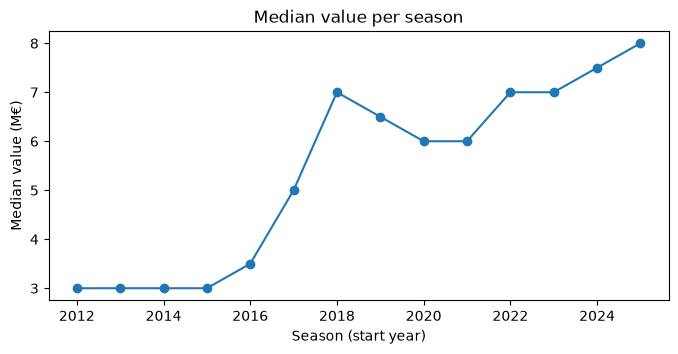

In [10]:
by_season = data.groupby("season").market_value_in_eur.median() / 1e6
ax = by_season.plot(marker="o", figsize=(8, 3.5), title="Median value per season")
ax.set(xlabel="Season (start year)", ylabel="Median value (M€)")
by_season

## 8. Missing values and correlations

In [11]:
print("Missing age:", data.age.isna().sum(), "| position 'Missing':", (data.position == "Missing").sum())
data[["log_value", "age", "minutes", "goals_per90", "season"]].corr()["log_value"].round(2)

Missing age: 19 | position 'Missing': 11


log_value      1.00
age           -0.39
minutes        0.34
goals_per90    0.31
season         0.25
Name: log_value, dtype: float64

## 9. Conclusions

Numbers from the run of 2026-11-04 (dataset current to 2026-07-06).

| Finding | Decision for `features.py` |
| --- | --- |
| 91.4 % of player-seasons have a valuation in the April–July window | Window confirmed; the rest are dropped |
| Value in euros is extremely skewed (mean ≈ 9.2 M€, max 200 M€); in log10 it is close to bell-shaped | Train on log(value), as planned |
| Below 450 minutes, goals per 90 reach absurd values (up to 30); with ≥ 450 the maximum is 1.6 | Keep the 450-minute threshold: 25,897 rows remain (28,734 with 200, 21,274 with 900) |
| Median value **does not peak at 25–27**: it is highest for 17–18 year-olds and falls steadily after 23. Teenagers only reach 450 minutes in a top-5 league when they are exceptional (selection bias) | Age is still a key feature (correlation −0.39 with log value), but the "peak at 25–27" hypothesis is rejected; explain this in the presentation |
| Premier League median ≈ 13 M€ vs. 3.5–5 M€ in the other leagues | League is a key feature |
| Forwards and midfielders ≈ 6 M€, defenders and goalkeepers ≈ 4 M€; 11 rows with position `Missing` | Position is a feature; drop the `Missing` rows |
| Median value grows from 3 M€ (2012–2015) to 8 M€ (2025) | Add the season as a feature (market inflation) |
| 19 rows without birth date | Drop them |
